# Synthetic Reaction Dataset Generator

Generate clean and noisy batch-reactor concentration data for six benchmark rate laws at multiple initial concentrations. Kinetic parameters are defined once at the reference concentration and remain unchanged across all initial concentrations.

## 1. Imports

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp

## 2. Experiment Configuration

The reference initial concentration is 0.05 mol/L. The rate-law parameters are calibrated once at this reference condition. The same parameters are used at 0.025, 0.05 and 0.075 mol/L.

In [2]:
reference_CA0 = 0.05
initial_concentrations = [0.025, 0.05, 0.075]
initial_rate = 0.005
saturation_K = 0.02

t_start = 0.0
t_end = 30.0
n_points = 121
t_eval = np.linspace(t_start, t_end, n_points)

noise_levels = [0.01, 0.03, 0.05]
n_replicates = 5
random_seed = 657
rng = np.random.default_rng(random_seed)

## 3. Define the Six Rate Laws

All rate constants are calculated using the reference initial concentration. They are not recalculated when the initial concentration changes.

In [3]:
rate_laws = {
    "First_Order": {
        "k": initial_rate / reference_CA0,
        "reaction_order": 1.0,
        "equation": "rate = k * CA"
    },
    "Second_Order": {
        "k": initial_rate / reference_CA0**2,
        "reaction_order": 2.0,
        "equation": "rate = k * CA**2"
    },
    "Fractional_Order": {
        "k": initial_rate / reference_CA0**1.5,
        "reaction_order": 1.5,
        "equation": "rate = k * CA**1.5"
    },
    "Saturation": {
        "Vmax": 0.007,
        "K": saturation_K,
        "reaction_order": np.nan,
        "equation": "rate = Vmax * CA / (K + CA)"
    },
    "Fourth_Order": {
        "k": initial_rate / reference_CA0**4,
        "reaction_order": 4.0,
        "equation": "rate = k * CA**4"
    },
    "Zero_Order": {
        "k": initial_rate,
        "reaction_order": 0.0,
        "equation": "rate = k"
    }
}

rate_laws

{'First_Order': {'k': 0.09999999999999999,
  'reaction_order': 1.0,
  'equation': 'rate = k * CA'},
 'Second_Order': {'k': 1.9999999999999996,
  'reaction_order': 2.0,
  'equation': 'rate = k * CA**2'},
 'Fractional_Order': {'k': 0.44721359549995787,
  'reaction_order': 1.5,
  'equation': 'rate = k * CA**1.5'},
 'Saturation': {'Vmax': 0.007,
  'K': 0.02,
  'reaction_order': nan,
  'equation': 'rate = Vmax * CA / (K + CA)'},
 'Fourth_Order': {'k': 799.9999999999999,
  'reaction_order': 4.0,
  'equation': 'rate = k * CA**4'},
 'Zero_Order': {'k': 0.005, 'reaction_order': 0.0, 'equation': 'rate = k'}}

## 4. Rate Evaluation and Batch-Reactor Simulation

In [4]:
def calculate_rate(CA, reaction, params):
    CA = max(float(CA), 0.0)

    if reaction == "First_Order":
        return params["k"] * CA
    if reaction == "Second_Order":
        return params["k"] * CA**2
    if reaction == "Fractional_Order":
        return params["k"] * CA**1.5
    if reaction == "Saturation":
        return params["Vmax"] * CA / (params["K"] + CA)
    if reaction == "Fourth_Order":
        return params["k"] * CA**4
    if reaction == "Zero_Order":
        return params["k"] if CA > 1e-12 else 0.0

    raise ValueError(f"Unknown reaction: {reaction}")


def simulate_profile(reaction, params, CA0, time_points):
    def ode_model(t, y):
        return [-calculate_rate(y[0], reaction, params)]

    def depletion_event(t, y):
        return float(y[0])

    depletion_event.terminal = True
    depletion_event.direction = -1

    solution = solve_ivp(
        ode_model,
        (float(time_points[0]), float(time_points[-1])),
        [float(CA0)],
        events=depletion_event,
        dense_output=True,
        rtol=1e-9,
        atol=1e-12
    )

    if not solution.success:
        raise RuntimeError(f"{reaction} at CA0={CA0}: {solution.message}")

    if len(solution.t_events[0]):
        depletion_time = solution.t_events[0][0]
        evaluation_times = np.minimum(time_points, depletion_time)
        CA_values = solution.sol(evaluation_times)[0]
        CA_values = np.where(time_points >= depletion_time, 0.0, CA_values)
    else:
        CA_values = solution.sol(time_points)[0]

    return np.maximum(CA_values, 0.0)

## 5. Verify Reference-Condition Rates

In [5]:
reference_rates = []

for reaction, params in rate_laws.items():
    current_rate = calculate_rate(reference_CA0, reaction, params)
    reference_rates.append({
        "Reaction": reaction,
        "Rate at reference CA0": current_rate
    })

display(pd.DataFrame(reference_rates))

,Reaction,Rate at reference CA0
0,First_Order,0.005
1,Second_Order,0.005
2,Fractional_Order,0.005
3,Saturation,0.005
4,Fourth_Order,0.005
5,Zero_Order,0.005


## 6. Generate Clean Concentration Trajectories

One clean trajectory is generated for every reaction and initial concentration.

In [6]:
clean_data = {}

for reaction, params in rate_laws.items():
    for CA0 in initial_concentrations:
        clean_data[(reaction, CA0)] = simulate_profile(
            reaction,
            params,
            CA0,
            t_eval
        )

print("Clean trajectories:", len(clean_data))

Clean trajectories: 18


## 7. Inspect Clean Trajectories

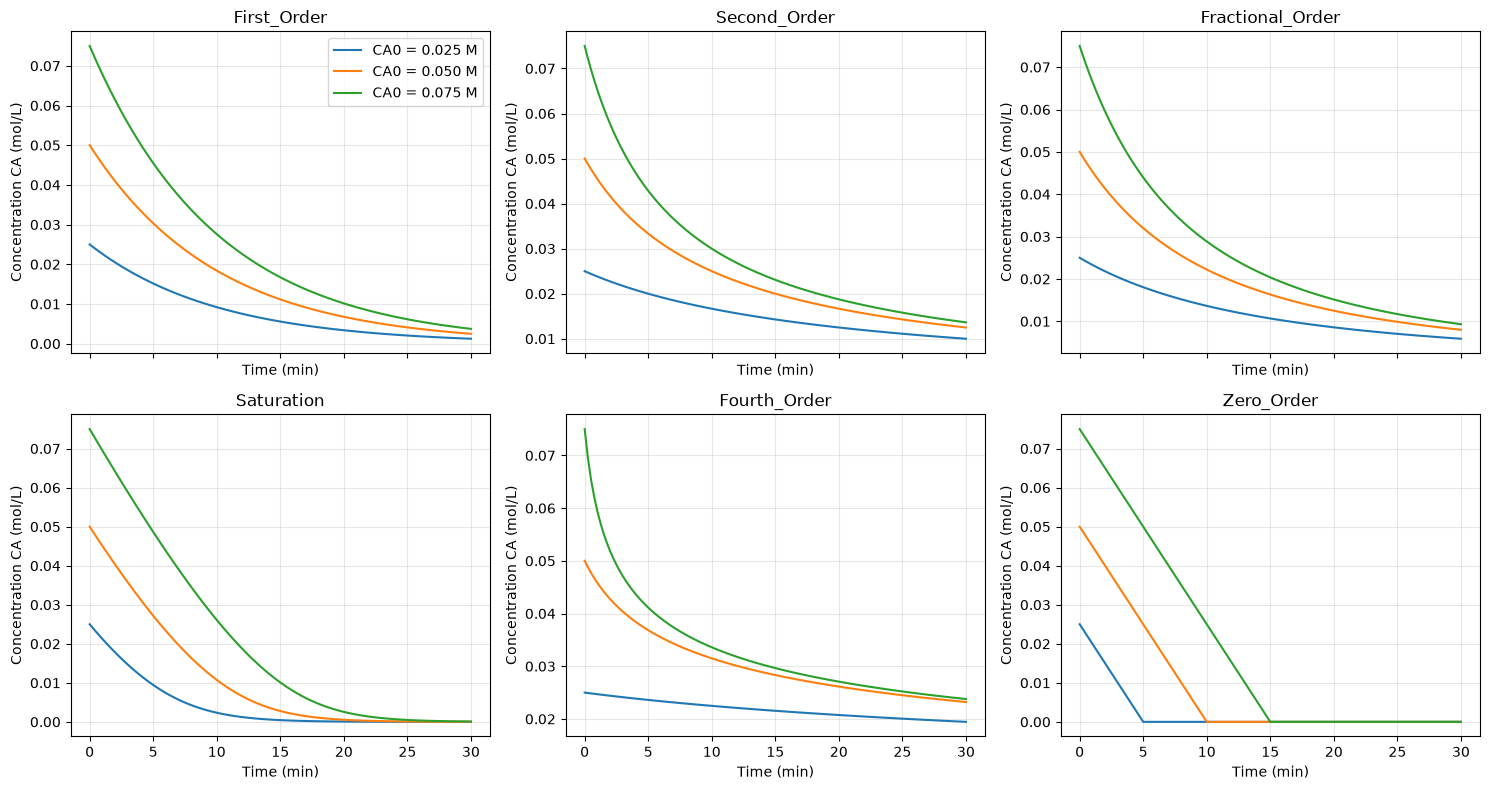

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True)

for ax, reaction in zip(axes.flat, rate_laws):
    for CA0 in initial_concentrations:
        ax.plot(
            t_eval,
            clean_data[(reaction, CA0)],
            label=f"CA0 = {CA0:.3f} M"
        )
    ax.set_title(reaction)
    ax.set_xlabel("Time (min)")
    ax.set_ylabel("Concentration CA (mol/L)")
    ax.grid(alpha=0.3)

axes[0, 0].legend()
plt.tight_layout()
plt.show()

## 8. Generate Noisy Measurements

For each initial concentration, the noise standard deviation is the specified noise fraction multiplied by that trajectory's initial concentration. Five independent replicates are generated at each nonzero noise level.

In [8]:
noisy_data = {}

for reaction in rate_laws:
    for CA0 in initial_concentrations:
        clean_CA = clean_data[(reaction, CA0)]
        noisy_data[(reaction, CA0)] = {}

        for noise in noise_levels:
            sigma = noise * CA0
            noisy_replicates = []

            for replicate in range(n_replicates):
                noise_values = rng.normal(0.0, sigma, size=len(clean_CA))
                noisy_replicates.append(clean_CA + noise_values)

            noisy_data[(reaction, CA0)][noise] = noisy_replicates

print("Noisy trajectory groups:", len(noisy_data))

Noisy trajectory groups: 18


## 9. Inspect Noise at Different Initial Concentrations

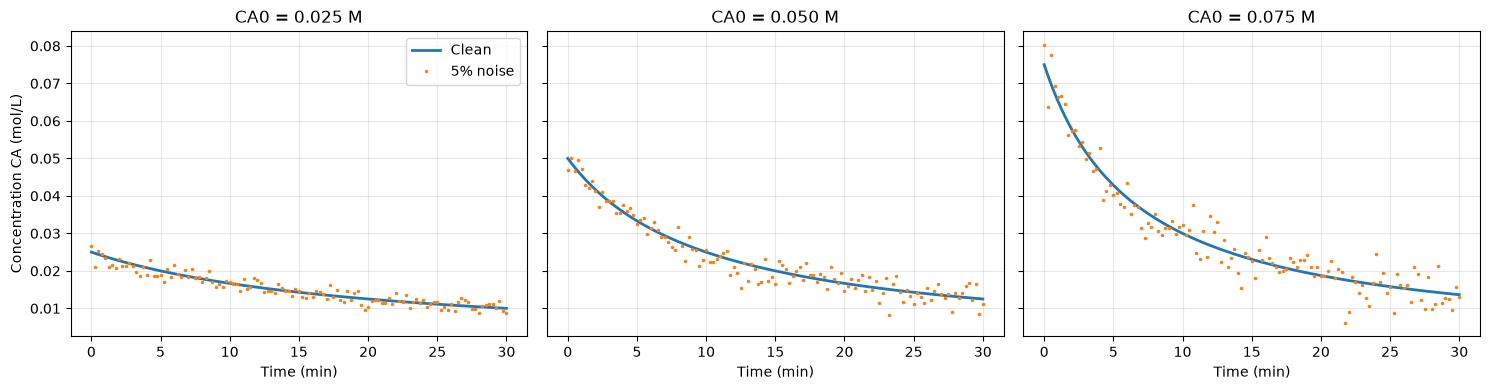

In [9]:
reaction_to_plot = "Second_Order"
noise_to_plot = 0.05

fig, axes = plt.subplots(1, len(initial_concentrations), figsize=(15, 4), sharey=True)

for ax, CA0 in zip(axes, initial_concentrations):
    ax.plot(
        t_eval,
        clean_data[(reaction_to_plot, CA0)],
        label="Clean",
        linewidth=2
    )
    ax.plot(
        t_eval,
        noisy_data[(reaction_to_plot, CA0)][noise_to_plot][0],
        ".",
        markersize=3,
        label="5% noise"
    )
    ax.set_title(f"CA0 = {CA0:.3f} M")
    ax.set_xlabel("Time (min)")
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Concentration CA (mol/L)")
axes[0].legend()
plt.tight_layout()
plt.show()

## 10. Build the Dataset

In [10]:
dataset = []

for reaction in rate_laws:
    for CA0 in initial_concentrations:
        CA_true = clean_data[(reaction, CA0)]

        for i, time_value in enumerate(t_eval):
            dataset.append({
                "reaction": reaction,
                "time_min": time_value,
                "noise_level": 0.0,
                "replicate": 0,
                "initial_concentration_mol_L": CA0,
                "CA_true": CA_true[i],
                "CA_observed": CA_true[i]
            })

        for noise in noise_levels:
            for replicate, CA_observed in enumerate(
                noisy_data[(reaction, CA0)][noise], start=1
            ):
                for i, time_value in enumerate(t_eval):
                    dataset.append({
                        "reaction": reaction,
                        "time_min": time_value,
                        "noise_level": noise,
                        "replicate": replicate,
                        "initial_concentration_mol_L": CA0,
                        "CA_true": CA_true[i],
                        "CA_observed": CA_observed[i]
                    })

df = pd.DataFrame(dataset)
display(df.head())

,reaction,time_min,noise_level,replicate,initial_concentration_mol_L,CA_true,CA_observed
0,First_Order,0.00,0.0,0,0.025,0.025000,0.025000
1,First_Order,0.25,0.0,0,0.025,0.024383,0.024383
2,First_Order,0.50,0.0,0,0.025,0.023781,0.023781
3,First_Order,0.75,0.0,0,0.025,0.023194,0.023194
4,First_Order,1.00,0.0,0,0.025,0.022621,0.022621


## 11. Validate the Generated Dataset

In [11]:
expected_rows = (
    len(rate_laws)
    * len(initial_concentrations)
    * (1 + len(noise_levels) * n_replicates)
    * n_points
)

print("Dataset shape:", df.shape)
print("Expected rows:", expected_rows)
print("Reactions:", sorted(df["reaction"].unique()))
print("Initial concentrations:", sorted(df["initial_concentration_mol_L"].unique()))
print("Noise levels:", sorted(df["noise_level"].unique()))
print("Replicates:", sorted(df["replicate"].unique()))
print("Missing values:", int(df.isna().sum().sum()))

assert len(df) == expected_rows
assert df.isna().sum().sum() == 0
assert df.groupby(
    ["reaction", "initial_concentration_mol_L", "noise_level", "replicate"]
).size().eq(n_points).all()

display(
    df.groupby(
        ["reaction", "initial_concentration_mol_L", "noise_level"]
    ).size().unstack()
)

Dataset shape: (34848, 7)
Expected rows: 34848
Reactions: ['First_Order', 'Fourth_Order', 'Fractional_Order', 'Saturation', 'Second_Order', 'Zero_Order']
Initial concentrations: [np.float64(0.025), np.float64(0.05), np.float64(0.075)]
Noise levels: [np.float64(0.0), np.float64(0.01), np.float64(0.03), np.float64(0.05)]
Replicates: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Missing values: 0


noise_level                                   0.00  0.01  0.03  0.05
reaction         initial_concentration_mol_L                        
First_Order      0.025                         121   605   605   605
                 0.050                         121   605   605   605
                 0.075                         121   605   605   605
Fourth_Order     0.025                         121   605   605   605
                 0.050                         121   605   605   605
                 0.075                         121   605   605   605
Fractional_Order 0.025                         121   605   605   605
                 0.050                         121   605   605   605
                 0.075                         121   605   605   605
Saturation       0.025                         121   605   605   605
                 0.050                         121   605   605   605
                 0.075                         121   605   605   605
Second_Order     0.025                         121   605   605   605
                 0.050                         121   605   605   605
                 0.075                         121   605   605   605
Zero_Order       0.025                         121   605   605   605
                 0.050                         121   605   605   605
                 0.075                         121   605   605   605

## 12. Export the Dataset and Rate-Law Parameters

The dataset includes the initial concentration for every trajectory. The parameter table contains one shared parameter set per reaction, defined at the reference initial concentration.

In [12]:
output_dir = Path("reaction_data")
output_dir.mkdir(parents=True, exist_ok=True)

dataset_path = output_dir / "reaction_dataset.csv"
parameters_path = output_dir / "rate_law_parameters.csv"
metadata_path = output_dir / "metadata.json"

df.to_csv(dataset_path, index=False)

parameter_rows = []

for reaction, params in rate_laws.items():
    parameter_rows.append({
        "reaction": reaction,
        "equation": params["equation"],
        "reaction_order": params["reaction_order"],
        "k": params.get("k", np.nan),
        "Vmax": params.get("Vmax", np.nan),
        "K": params.get("K", np.nan),
        "reference_initial_concentration_mol_L": reference_CA0,
        "reference_initial_rate_mol_L_min": initial_rate
    })

parameters_df = pd.DataFrame(parameter_rows)
parameters_df.to_csv(parameters_path, index=False)

metadata = {
    "reference_initial_concentration_mol_L": reference_CA0,
    "initial_concentrations_mol_L": initial_concentrations,
    "reference_initial_rate_mol_L_min": initial_rate,
    "duration_min": t_end,
    "number_of_time_points": n_points,
    "noise_levels_fraction_of_initial_concentration": noise_levels,
    "noise_model": "additive Gaussian noise with sigma equal to noise fraction times trajectory CA0",
    "noisy_replicates_per_noise_level": n_replicates,
    "random_seed": random_seed,
    "kinetic_parameters_shared_across_initial_concentrations": True
}

metadata_path.write_text(json.dumps(metadata, indent=2), encoding="utf-8")

print("Exported:")
print(dataset_path.resolve())
print(parameters_path.resolve())
print(metadata_path.resolve())

display(parameters_df)

Exported:
C:\F\CHE657 Term Project\reaction_data\reaction_dataset.csv
C:\F\CHE657 Term Project\reaction_data\rate_law_parameters.csv
C:\F\CHE657 Term Project\reaction_data\metadata.json


,reaction,equation,reaction_order,k,Vmax,K,reference_initial_concentration_mol_L,reference_initial_rate_mol_L_min
0,First_Order,rate = k * CA,1.0,0.100000,NaN,NaN,0.05,0.005
1,Second_Order,rate = k * CA**2,2.0,2.000000,NaN,NaN,0.05,0.005
2,Fractional_Order,rate = k * CA**1.5,1.5,0.447214,NaN,NaN,0.05,0.005
3,Saturation,rate = Vmax * CA / (K + CA),NaN,NaN,0.007,0.02,0.05,0.005
4,Fourth_Order,rate = k * CA**4,4.0,800.000000,NaN,NaN,0.05,0.005
5,Zero_Order,rate = k,0.0,0.005000,NaN,NaN,0.05,0.005
